In [70]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import time

# ***Question 1 (20 points) — Pipeline and EDA***

## (a) (4 pts) Load the provided cleaned train/test CSVs and keep the time split.

In [71]:
train_df = pd.read_csv('sample_data/hw3_train.csv')
train_df

,acc_now_delinq,addr_state,annual_inc,application_type,collections_12_mths_ex_med,delinq_2yrs,dti,earliest_cr_line,emp_length,emp_title,...,revol_bal,revol_util,term,title,tot_coll_amt,tot_cur_bal,total_acc,total_rev_hi_lim,zip_code,default_flag
0,0.0,AZ,24000.0,INDIVIDUAL,0.0,0.0,27.65,Jan-1985,10+ YEARS,NaN,...,13648.0,83.7,36 MONTHS,Computer,NaN,NaN,9.0,NaN,860xx,0
1,0.0,GA,30000.0,INDIVIDUAL,0.0,0.0,1.00,Apr-1999,< 1 YEAR,Ryder,...,1687.0,9.4,60 MONTHS,bike,NaN,NaN,4.0,NaN,309xx,1
2,0.0,IL,12252.0,INDIVIDUAL,0.0,0.0,8.72,Nov-2001,10+ YEARS,NaN,...,2956.0,98.5,36 MONTHS,real estate business,NaN,NaN,10.0,NaN,606xx,0
3,0.0,CA,49200.0,INDIVIDUAL,0.0,0.0,20.00,Feb-1996,10+ YEARS,AIR RESOURCES BOARD,...,5598.0,21.0,36 MONTHS,personel,NaN,NaN,37.0,NaN,917xx,0
4,0.0,AZ,36000.0,INDIVIDUAL,0.0,0.0,11.20,Nov-2004,3 YEARS,Veolia Transportaton,...,7963.0,28.3,36 MONTHS,My wedding loan I promise to pay back,NaN,NaN,12.0,NaN,852xx,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
256934,0.0,CO,48000.0,INDIVIDUAL,0.0,0.0,36.93,Aug-1990,10+ YEARS,supervisor,...,12943.0,63.4,36 MONTHS,Medical expenses,0.0,207975.0,45.0,20400.0,810xx,1
256935,0.0,FL,54000.0,INDIVIDUAL,0.0,1.0,13.22,Nov-1975,< 1 YEAR,Coordinator of RSVP,...,10776.0,25.8,36 MONTHS,Debt consolidation,0.0,24696.0,21.0,41700.0,325xx,0
256936,0.0,FL,27000.0,INDIVIDUAL,0.0,0.0,18.58,Feb-2011,2 YEARS,Painter,...,1756.0,97.6,36 MONTHS,Debt consolidation,0.0,8357.0,4.0,1800.0,330xx,0
256937,0.0,CA,50000.0,INDIVIDUAL,0.0,0.0,12.63,Sep-2002,10+ YEARS,Lead Custodian,...,1700.0,5.6,36 MONTHS,Car financing,0.0,18979.0,30.0,30100.0,956xx,0


In [72]:
test_df = pd.read_csv('sample_data/hw3_test.csv')
test_df

,acc_now_delinq,addr_state,annual_inc,application_type,collections_12_mths_ex_med,delinq_2yrs,dti,earliest_cr_line,emp_length,emp_title,...,revol_bal,revol_util,term,title,tot_coll_amt,tot_cur_bal,total_acc,total_rev_hi_lim,zip_code,default_flag
0,0,CA,153000.0,INDIVIDUAL,0,0,16.99,Jul-1994,6 YEARS,Solutions Architect,...,8550.0,22.7,36 MONTHS,Credit card refinancing,0.0,442731.0,46,37600.0,923xx,0
1,0,WA,50000.0,INDIVIDUAL,0,0,6.07,Jan-2000,2 YEARS,Pse,...,3560.0,98.9,36 MONTHS,Debt consolidation,0.0,5588.0,5,3600.0,985xx,0
2,0,TX,110000.0,INDIVIDUAL,0,0,13.12,Mar-2013,7 YEARS,Associate Director,...,23348.0,27.2,36 MONTHS,Debt consolidation,0.0,276461.0,27,85700.0,750xx,0
3,0,CA,51979.0,INDIVIDUAL,0,0,10.11,Aug-2006,7 YEARS,Biller,...,5733.0,20.0,60 MONTHS,Debt consolidation,251.0,10956.0,21,28700.0,958xx,0
4,0,MA,75000.0,INDIVIDUAL,0,1,10.86,May-2008,7 YEARS,cdl driver,...,2700.0,90.0,36 MONTHS,Debt consolidation,0.0,127645.0,10,3000.0,026xx,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
167946,0,SC,60000.0,INDIVIDUAL,0,0,32.34,Jan-1999,4 YEARS,Process Control Inspector,...,5955.0,58.4,36 MONTHS,Debt consolidation,0.0,47608.0,29,10200.0,292xx,1
167947,0,GA,20000.0,INDIVIDUAL,0,0,29.11,Nov-2004,NaN,NaN,...,2213.0,92.2,36 MONTHS,Debt consolidation,0.0,129982.0,31,2400.0,302xx,1
167948,0,NY,85000.0,INDIVIDUAL,0,0,2.85,Jan-1993,10+ YEARS,investment,...,5989.0,32.7,36 MONTHS,Moving and relocation,508.0,5989.0,8,18300.0,104xx,0
167949,0,SC,65000.0,INDIVIDUAL,0,0,17.54,Sep-1999,10+ YEARS,supervisor,...,10914.0,81.4,60 MONTHS,Debt consolidation,0.0,32127.0,16,13400.0,293xx,1


## b/ Identify any issues that need to be fixed before modeling

In [73]:
train_df['term_months'] = train_df['term'].str.extract('(\d+)').fillna(0).astype(float)
train_df['emp_length_years'] = train_df['emp_length'].str.extract('(\d+)').fillna(0).astype(float)
train_df['emp_title']= train_df['emp_title'].fillna('Unknown')
train_df

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_6571/170817626.py:1: SyntaxWarning: invalid escape sequence '\d'
  train_df['term_months'] = train_df['term'].str.extract('(\d+)').fillna(0).astype(float)
/tmp/ipykernel_6571/170817626.py:2: SyntaxWarning: invalid escape sequence '\d'
  train_df['emp_length_years'] = train_df['emp_length'].str.extract('(\d+)').fillna(0).astype(float)


,acc_now_delinq,addr_state,annual_inc,application_type,collections_12_mths_ex_med,delinq_2yrs,dti,earliest_cr_line,emp_length,emp_title,...,term,title,tot_coll_amt,tot_cur_bal,total_acc,total_rev_hi_lim,zip_code,default_flag,term_months,emp_length_years
0,0.0,AZ,24000.0,INDIVIDUAL,0.0,0.0,27.65,Jan-1985,10+ YEARS,Unknown,...,36 MONTHS,Computer,NaN,NaN,9.0,NaN,860xx,0,36.0,10.0
1,0.0,GA,30000.0,INDIVIDUAL,0.0,0.0,1.00,Apr-1999,< 1 YEAR,Ryder,...,60 MONTHS,bike,NaN,NaN,4.0,NaN,309xx,1,60.0,1.0
2,0.0,IL,12252.0,INDIVIDUAL,0.0,0.0,8.72,Nov-2001,10+ YEARS,Unknown,...,36 MONTHS,real estate business,NaN,NaN,10.0,NaN,606xx,0,36.0,10.0
3,0.0,CA,49200.0,INDIVIDUAL,0.0,0.0,20.00,Feb-1996,10+ YEARS,AIR RESOURCES BOARD,...,36 MONTHS,personel,NaN,NaN,37.0,NaN,917xx,0,36.0,10.0
4,0.0,AZ,36000.0,INDIVIDUAL,0.0,0.0,11.20,Nov-2004,3 YEARS,Veolia Transportaton,...,36 MONTHS,My wedding loan I promise to pay back,NaN,NaN,12.0,NaN,852xx,0,36.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
256934,0.0,CO,48000.0,INDIVIDUAL,0.0,0.0,36.93,Aug-1990,10+ YEARS,supervisor,...,36 MONTHS,Medical expenses,0.0,207975.0,45.0,20400.0,810xx,1,36.0,10.0
256935,0.0,FL,54000.0,INDIVIDUAL,0.0,1.0,13.22,Nov-1975,< 1 YEAR,Coordinator of RSVP,...,36 MONTHS,Debt consolidation,0.0,24696.0,21.0,41700.0,325xx,0,36.0,1.0
256936,0.0,FL,27000.0,INDIVIDUAL,0.0,0.0,18.58,Feb-2011,2 YEARS,Painter,...,36 MONTHS,Debt consolidation,0.0,8357.0,4.0,1800.0,330xx,0,36.0,2.0
256937,0.0,CA,50000.0,INDIVIDUAL,0.0,0.0,12.63,Sep-2002,10+ YEARS,Lead Custodian,...,36 MONTHS,Car financing,0.0,18979.0,30.0,30100.0,956xx,0,36.0,10.0


In [74]:
test_df['term_months'] = test_df['term'].str.extract('(\d+)').fillna(0).astype(float)
test_df['emp_length_years'] = test_df['emp_length'].str.extract('(\d+)').fillna(0).astype(float)
test_df['emp_title']= test_df['emp_title'].fillna('Unknown')
test_df

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_6571/3937803391.py:1: SyntaxWarning: invalid escape sequence '\d'
  test_df['term_months'] = test_df['term'].str.extract('(\d+)').fillna(0).astype(float)
/tmp/ipykernel_6571/3937803391.py:2: SyntaxWarning: invalid escape sequence '\d'
  test_df['emp_length_years'] = test_df['emp_length'].str.extract('(\d+)').fillna(0).astype(float)


,acc_now_delinq,addr_state,annual_inc,application_type,collections_12_mths_ex_med,delinq_2yrs,dti,earliest_cr_line,emp_length,emp_title,...,term,title,tot_coll_amt,tot_cur_bal,total_acc,total_rev_hi_lim,zip_code,default_flag,term_months,emp_length_years
0,0,CA,153000.0,INDIVIDUAL,0,0,16.99,Jul-1994,6 YEARS,Solutions Architect,...,36 MONTHS,Credit card refinancing,0.0,442731.0,46,37600.0,923xx,0,36.0,6.0
1,0,WA,50000.0,INDIVIDUAL,0,0,6.07,Jan-2000,2 YEARS,Pse,...,36 MONTHS,Debt consolidation,0.0,5588.0,5,3600.0,985xx,0,36.0,2.0
2,0,TX,110000.0,INDIVIDUAL,0,0,13.12,Mar-2013,7 YEARS,Associate Director,...,36 MONTHS,Debt consolidation,0.0,276461.0,27,85700.0,750xx,0,36.0,7.0
3,0,CA,51979.0,INDIVIDUAL,0,0,10.11,Aug-2006,7 YEARS,Biller,...,60 MONTHS,Debt consolidation,251.0,10956.0,21,28700.0,958xx,0,60.0,7.0
4,0,MA,75000.0,INDIVIDUAL,0,1,10.86,May-2008,7 YEARS,cdl driver,...,36 MONTHS,Debt consolidation,0.0,127645.0,10,3000.0,026xx,0,36.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
167946,0,SC,60000.0,INDIVIDUAL,0,0,32.34,Jan-1999,4 YEARS,Process Control Inspector,...,36 MONTHS,Debt consolidation,0.0,47608.0,29,10200.0,292xx,1,36.0,4.0
167947,0,GA,20000.0,INDIVIDUAL,0,0,29.11,Nov-2004,NaN,Unknown,...,36 MONTHS,Debt consolidation,0.0,129982.0,31,2400.0,302xx,1,36.0,0.0
167948,0,NY,85000.0,INDIVIDUAL,0,0,2.85,Jan-1993,10+ YEARS,investment,...,36 MONTHS,Moving and relocation,508.0,5989.0,8,18300.0,104xx,0,36.0,10.0
167949,0,SC,65000.0,INDIVIDUAL,0,0,17.54,Sep-1999,10+ YEARS,supervisor,...,60 MONTHS,Debt consolidation,0.0,32127.0,16,13400.0,293xx,1,60.0,10.0


# (c) (4 pts) Report rows, column count, and default rate for train and test.

In [75]:
train_rows, train_cols = train_df.shape
test_rows, test_cols = test_df.shape

train_default_rate = train_df['default_flag'].mean()
test_default_rate = test_df['default_flag'].mean()

print(f"TRAIN: {train_rows} rows, {train_cols} columns, {train_default_rate:.2%} default rate")
print(f"TEST: {test_rows} rows, {test_cols} columns, {test_default_rate:.2%} default rate")

TRAIN: 256939 rows, 33 columns, 18.38% default rate
TEST: 167951 rows, 33 columns, 22.17% default rate


# (d) (4 pts) Using training data, show at least four borrower or loan features, including at least one explicit derived variable, and give brief takeaways.

In [76]:
#One explicit derived variable
train_df["income_vs_total_account"] = train_df['annual_inc'] / train_df["total_acc"]
train_df["income_vs_total_account"]

,income_vs_total_account
0,2666.666667
1,7500.000000
2,1225.200000
3,1329.729730
4,3000.000000
...,...
256934,1066.666667
256935,2571.428571
256936,6750.000000
256937,1666.666667


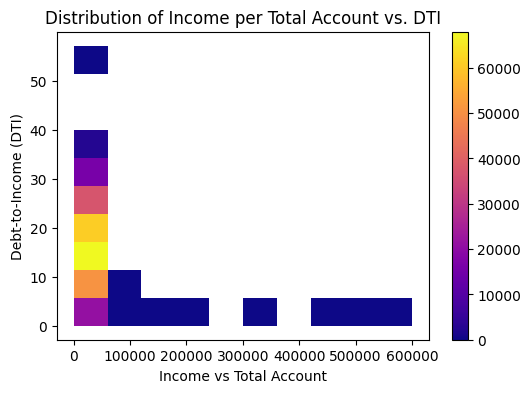

In [130]:
import matplotlib.pyplot as plt
import seaborn as sns

# Feature 1: Income vs Total Account and DTI (Debt-to-Income)
plt.figure(figsize=(6,4))
sns.histplot(data=train_df, x="income_vs_total_account", y='dti', bins=10, cmap="plasma", cbar=True)
plt.title('Distribution of Income per Total Account vs. DTI')
plt.xlabel('Income vs Total Account')
plt.ylabel('Debt-to-Income (DTI)')
plt.show()

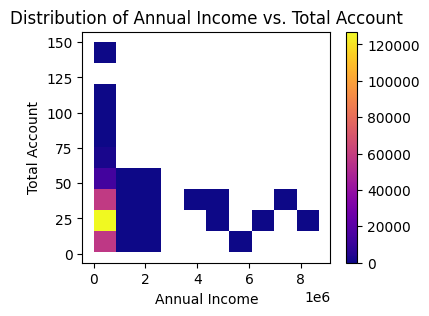

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

# Feature 2: Annual Income and Number of Accounts
plt.figure(figsize=(4,3))
sns.histplot(data=train_df, x = 'annual_inc', y = 'total_acc', bins=10, cmap="plasma", cbar=True)
plt.title('Distribution of Annual Income vs. Total Account')
plt.xlabel('Annual Income')
plt.ylabel('Total Account')
plt.show()

/tmp/ipykernel_6571/77522738.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_df, x = 'purpose', y = 'loan_amnt', palette='viridis', order=train_df.groupby('purpose')['loan_amnt'].mean().sort_values(ascending=False).index)


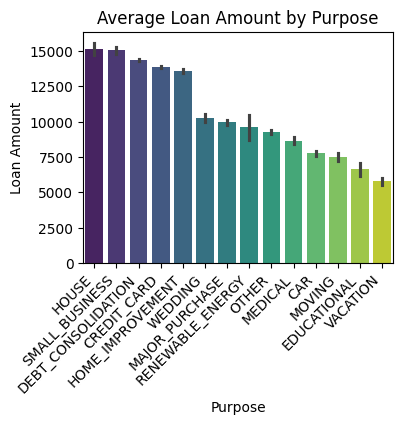

In [129]:
# Feature 3: Loan Amount by Purpose
plt.figure(figsize=(4,3))
sns.barplot(data=train_df, x = 'purpose', y = 'loan_amnt', palette='viridis', order=train_df.groupby('purpose')['loan_amnt'].mean().sort_values(ascending=False).index)
plt.title('Average Loan Amount by Purpose')
plt.xlabel('Purpose')
plt.ylabel('Loan Amount')
plt.xticks(rotation=45, ha='right')
plt.show()

/tmp/ipykernel_6571/3868369725.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_df, x = 'home_ownership', y = 'emp_length_years', palette='viridis', order=train_df.groupby('home_ownership')['emp_length_years'].mean().sort_values(ascending=False).index)


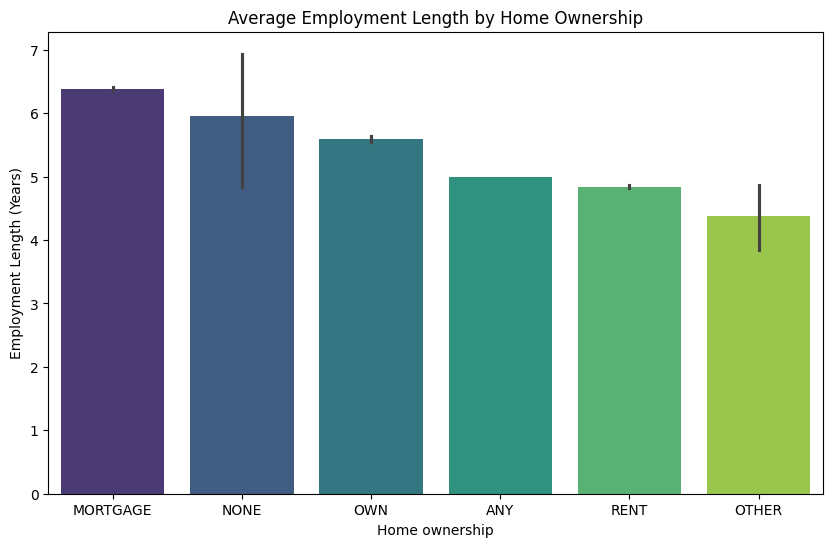

In [80]:
# Feature 4: Employment Length by Home Ownership
plt.figure(figsize=(10,6))
sns.barplot(data=train_df, x = 'home_ownership', y = 'emp_length_years', palette='viridis', order=train_df.groupby('home_ownership')['emp_length_years'].mean().sort_values(ascending=False).index)
plt.title('Average Employment Length by Home Ownership')
plt.xlabel('Home ownership')
plt.ylabel('Employment Length (Years)')
plt.show()

Take away:

1.  **Income vs. Total Account and Debt-to-Income (DTI)**: Borrowers with a higher `income_vs_total_account` (more income per active credit account) and lower `dti` (less debt burden relative to income) generally appear to be less risky.
2.  **Annual Income vs. Total Accounts**: There appears to be a positive correlation between annual income and the total number of credit accounts. Individuals with higher incomes often manage a larger number of credit lines, which could indicate greater financial activity or access to credit.

3.  **Loan Amount vs. Purpose**: Certain loan purposes, such as 'debt consolidation' and 'home improvement', tend to be associated with higher average loan amounts.

4.  **Home Ownership vs. Employment Length**: Borrowers who own a home (MORTGAGE or OWN) generally show longer average employment lengths compared to those who rent or have other home ownership statuses. This indicates a potential link between long-term employment stability and home ownership.

# (e) (4 pts) Using training data, compare default rates for at least two categorical groups, add one multivariable summary, and name the raw or explicitly derived features that appear most informative from your EDA.

Default Rates by home_ownership :
 home_ownership
ANY         0.000000
MORTGAGE    0.163699
NONE        0.166667
OTHER       0.212291
OWN         0.187775
RENT        0.206564
Name: default_flag, dtype: float64 

Default Rates by purpose :
 purpose
CAR                   0.126613
CREDIT_CARD           0.160477
DEBT_CONSOLIDATION    0.190885
EDUCATIONAL           0.208531
HOME_IMPROVEMENT      0.157143
HOUSE                 0.178509
MAJOR_PURCHASE        0.142299
MEDICAL               0.207038
MOVING                0.216307
OTHER                 0.211432
RENEWABLE_ENERGY      0.203704
SMALL_BUSINESS        0.296793
VACATION              0.175851
WEDDING               0.138240
Name: default_flag, dtype: float64 



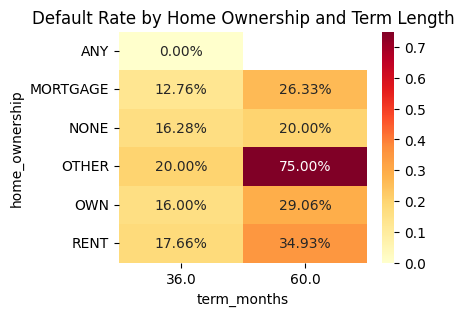

In [81]:
cat_groups = ['home_ownership', 'purpose']

for cat in cat_groups:
  comparison = train_df.groupby(cat)['default_flag'].mean()
  print(f"Default Rates by {cat} :\n {comparison} \n")
plt.figure(figsize=(4,3))
pivot_table = train_df.pivot_table(values='default_flag',index='home_ownership',
                                   columns='term_months',aggfunc='mean')
sns.heatmap(pivot_table, annot=True,cmap='YlOrRd',fmt='.2%')
plt.title('Default Rate by Home Ownership and Term Length')
plt.show()

In [82]:
# Identifying Informative Features
informative_raw = ['purpose', 'home_ownership']
informative_derived = ['term_months']

# **Question 2 (20 points) — KNN**

# (a) (4 pts) Build KNN-ready inputs using the same shared feature set, choose a numeric feature subset, justify scaling, and if needed use a fixed training subset for tractability.

In [83]:
from sklearn.preprocessing import StandardScaler

features = ['annual_inc', 'dti', 'total_acc', 'loan_amnt', 'term_months', 'emp_length_years']

X_train_raw = train_df[features].fillna(0)
y_train = train_df['default_flag']

X_train_sub = X_train_raw.sample(2000, random_state = 42)
y_train_sub = y_train.loc[X_train_sub.index]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_sub)

X_test_scaled = scaler.transform(test_df[features].fillna(0))


### Justification for Scaling

KNN is a 'distance-based' algorithm. This means features with larger numbers can unfairly dominate the results. Scaling ensures all features have a similar impact, leading to a more accurate model. This makes sure all features have a mean of 0 and a standard deviation of 1.

# (b) (4 pts) Try several k values and describe a training-only temporal validation plan. If you preprocess during validation, fit that preprocessing on the earlier development period only.

In [84]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [85]:
train_df['issue_d'] = pd.to_datetime(train_df['issue_d'])
split_date = '2014-01-01'
dev_period = train_df[train_df['issue_d'] < split_date].copy()
val_period = train_df[train_df['issue_d'] < split_date].copy()

/tmp/ipykernel_6571/590275415.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  train_df['issue_d'] = pd.to_datetime(train_df['issue_d'])


In [86]:
features = ['annual_inc', 'dti', 'total_acc', 'loan_amnt', 'term_months', 'emp_length_years']

#Making the task tractable
dev_sub = dev_period.sample(2000, random_state = 42)

X_dev_raw = dev_sub[features].fillna(0)
y_dev = dev_sub['default_flag']

X_val_raw = val_period[features].fillna(0)
y_val = val_period['default_flag']

In [87]:
scaler = StandardScaler()
X_dev_scaled = scaler.fit_transform(X_dev_raw)
X_val_scaled = scaler.fit_transform(X_val_raw)

In [88]:
k_values = [1,3,5,7,21,50,89]
results = []

for k in k_values:
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(X_dev_scaled, y_dev)

# (c) (4 pts) Report validation results for all candidate k values in one compact table.

In [89]:
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_dev_scaled, y_dev)

    # Check how accurate  is on the newer validation set
    y_pred = knn.predict(X_val_scaled)
    acc = accuracy_score(y_val, y_pred)
    results.append({'k': k, 'Validation Accuracy': acc})
results_table = pd.DataFrame(results)
print(results_table.to_string(index=False))

 k  Validation Accuracy
 1             0.714895
 3             0.764379
 5             0.785489
 7             0.797490
21             0.813200
50             0.817386
89             0.817497


# (d) (4 pts) Choose k from validation only, refit the selected KNN specification on the chosen training subset, and test it once.

In [90]:
best_k = 89

#Fit the model on the chosen training subset
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train_scaled, y_train_sub)

KNeighborsClassifier(n_neighbors=89)

In [91]:
test_df = test_df.dropna(subset=['default_flag'])

In [92]:
X_test_raw = test_df[features].fillna(0)

X_test_scaled = scaler.transform(X_test_raw)

y_test = test_df['default_flag']
#Predict
y_test_pred = final_knn.predict(X_test_scaled)

final_test_accuracy = accuracy_score(y_test, y_test_pred)

final_test_accuracy

0.7783103405159838

# (e) (4 pts) Use multiple metrics to say whether KNN is useful here, and note any computational limitation.

In [93]:
y_test_prob = final_knn.predict_proba(X_test_scaled)[:,1]

In [94]:
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
auc = roc_auc_score(y_test, y_test_prob)

print("KNN Test Performance:")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"AUC      : {auc:.4f}")

KNN Test Performance:
Accuracy : 0.7783
Precision: 0.0000
Recall   : 0.0000
AUC      : 0.6099


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Although the KNN model achieves high accuracy (~80%), its recall is extremely low, indicating that it fails to identify most default cases. This suggests that the model is biased toward predicting non-default due to class imbalance. In a lending context, this is problematic because failing to detect defaults can lead to significant financial losses.

KNN is computationally expensive because it must compute distances to all training points at prediction time. With a large dataset (~250k observations), this leads to slow inference and high memory usage, making it impractical for real-time lending decisions

# **Question 3 (20 points) — SVM and LDA**

# (a) (4 pts) Use the same target and the same raw plus explicitly derived feature set for both models; justify any simplification without using test results.

Both models will use the same target variable, which is default_flag.

Both model will also use the same set of predictors variables in the features set.

This will wnsure SVM and LDA are trained on identical input, making it easier for comparison.

In [95]:
features = ['annual_inc', 'dti', 'total_acc', 'loan_amnt', 'term_months', 'emp_length_years']
target = 'default_flag'

# Prepare data for temporal validation consistent with KNN
# Using dev_period for development and val_period for validation, as done for KNN
X_dev_svm_lda = dev_period[features].fillna(0)
y_dev_svm_lda = dev_period[target]

X_val_svm_lda = val_period[features].fillna(0)
y_val_svm_lda = val_period[target]

# For final model fitting on the full training subset used in KNN (if applicable) or full train_df
# Let's use the full train_df for final fitting for now, and subsample later if needed for tractability
X_train_full_svm_lda = train_df[features].fillna(0)
y_train_full_svm_lda = train_df[target]

# Test set features and target
X_test_svm_lda = test_df[features].fillna(0)
y_test_svm_lda = test_df[target]

print(f"Features used: {features}")
print(f"Target variable: {target}")

Features used: ['annual_inc', 'dti', 'total_acc', 'loan_amnt', 'term_months', 'emp_length_years']
Target variable: default_flag


# (b) (4 pts) Fit the SVM with train-fitted preprocessing and report the key settings. If the default 0.5 threshold is not appropriate given the target distribution you observed in Question 1, choose a classification threshold using validation only.

In [96]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report

In [97]:
svm_model = SVC(C=1.0, kernel = 'rbf', probability = True)
svm_model.fit(X_dev_scaled, y_dev)

probs_val = svm_model.predict_proba(X_val_scaled)[:,1]

In [98]:
#choose threshold = 0.3 to capture more risky loans
new_threshold = 0.3
preds_custom = (probs_val >= new_threshold).astype(int)

print(classification_report(y_val, preds_custom))

              precision    recall  f1-score   support

           0       0.82      0.98      0.89    132014
           1       0.36      0.05      0.09     29474

    accuracy                           0.81    161488
   macro avg       0.59      0.52      0.49    161488
weighted avg       0.74      0.81      0.75    161488



# (c) (4 pts) Fit the LDA on the same inputs and report the key settings. Use the same thresholdselection approach as in (b) so the comparison is fair.

In [99]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [100]:
lda = LinearDiscriminantAnalysis(solver = 'svd')
lda.fit(X_dev_scaled, y_dev)

probs_lda_val = lda.predict_proba(X_val_scaled)[:,1]

In [101]:
lda_threshold = 0.3
preds_lda_custom = (probs_lda_val > lda_threshold).astype(int)

print(classification_report(y_val,preds_lda_custom))

              precision    recall  f1-score   support

           0       0.85      0.86      0.85    132014
           1       0.33      0.31      0.32     29474

    accuracy                           0.76    161488
   macro avg       0.59      0.59      0.59    161488
weighted avg       0.75      0.76      0.76    161488



==> LDA produced better recall rates.

# (d) (4 pts) Evaluate both models on the same untouched test set and report one common metric table.

In [102]:
X_test_raw = test_df[features].fillna(0)
y_test = test_df['default_flag']

In [103]:
#Scale the raw test data
X_test_scaled = scaler.transform(X_test_raw)

In [104]:
threshold = 0.3

In [105]:
#SVM
svm_probs = svm_model.predict_proba(X_test_scaled)[:, 1]
svm_preds = (svm_probs >= threshold).astype(int)

In [106]:
#LDA Predictions
lda_probs = lda.predict_proba(X_test_scaled)[:,1]
lda_preds = (lda_probs > threshold).astype(int)

In [107]:
models = ['SVM (C=1.0)', 'LDA (SVD)']
preds = [svm_preds, lda_preds]

In [108]:
results = []
for name, pred in zip (models,preds):
  results.append({
      "Model": name,
      'Accuracy': accuracy_score(y_test,pred),
      'Precision': precision_score(y_test,pred),
      'Recall': recall_score(y_test,pred),
      'AUC': roc_auc_score(y_test,pred)
  })

results_table = pd.DataFrame(results)
results_table

,Model,Accuracy,Precision,Recall,AUC
0,SVM (C=1.0),0.767379,0.331745,0.048613,0.510360
1,LDA (SVD),0.695757,0.317580,0.324148,0.562876


# (e) (4 pts) Choose the better model and explain which test metrics drive your decision. If different metrics point in different directions, say why.

LDA is better is it has better Recall and Precision metrics.

Because Recall let us know how we are filtering risky loans, the higher the recall, the higher percentage we catch risky loan. Additionally, Precision tell us the correct defaults we actually predict, which also highlights the posibility of eliminating False Negative in our prediction.

If metrics point in different directions (for example, if we use precision metric, we will choose SVM model), this will make us eliminate some profitable customer. However, the goal is to identify risky loan, so recall is the determined factor in choosing suitable model.

## **Question 4 (20 points) — Decision Tree**

# (a) (5 pts) Define the tree inputs using the same predictor set, and choose at least one complexity control.

In [109]:
from sklearn.tree import DecisionTreeClassifier

In [110]:
y_train = train_df['default_flag'].fillna(0)
y_test = test_df['default_flag'].fillna(0)

In [111]:
features = ['annual_inc', 'dti', 'total_acc', 'loan_amnt', 'term_months', 'emp_length_years']

In [112]:
X_train = train_df[features].fillna(0)
X_test = test_df[features].fillna(0)

In [113]:
tree_model = DecisionTreeClassifier(max_depth = 5, min_samples_leaf = 100, random_state = 42)
tree_model.fit(X_train, y_train)



DecisionTreeClassifier(max_depth=5, min_samples_leaf=100, random_state=42)

# (b) (5 pts) Try several complexity settings with training-only temporal validation. If you encode or impute during validation, fit that preprocessing on the development period only.

In [114]:
depths = [2,3,5,7,9,20,30]
tree_results = []

In [115]:
for d in depths:
  dtree = DecisionTreeClassifier(max_depth = d, random_state = 42)
  dtree.fit(X_dev_scaled, y_dev)

  val_acc = dtree.score(X_val_scaled, y_val)
  tree_results.append({'Depth': d, 'Validation Accuracy': val_acc})

tree_results_table = pd.DataFrame(tree_results)
tree_results_table

,Depth,Validation Accuracy
0,2,0.809837
1,3,0.812878
2,5,0.804766
3,7,0.800233
4,9,0.770596
5,20,0.681611
6,30,0.679444


# (c) (5 pts) Fit the selected tree on the full training set with the chosen specification, and evaluate it once on the untouched test set.

In [116]:
best_depth = 3

final_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
final_tree.fit(X_train_raw, y_train)

X_test_final = test_df[features].fillna(train_df[features].median())
y_test_final = test_df['default_flag']

In [117]:
y_test_preds = final_tree.predict(X_test_final)
final_acc = accuracy_score(y_test_final, y_test_preds)

print(f"--- Final Decision Tree Results (Depth={best_depth}) ---")
print(f"Final Test Accuracy: {final_acc:.2%}")
print("\nClassification Report:")
print(classification_report(y_test_final, y_test_preds))

--- Final Decision Tree Results (Depth=3) ---
Final Test Accuracy: 77.83%

Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88    130718
           1       0.00      0.00      0.00     37233

    accuracy                           0.78    167951
   macro avg       0.39      0.50      0.44    167951
weighted avg       0.61      0.78      0.68    167951



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# (d) (5 pts) Show the most important variables, a few representative rules, and what they suggest about borrower risk.

In [118]:
# To see the actual importance scores:
important_variable = pd.Series(final_tree.feature_importances_, index=features)
print(important_variable.sort_values(ascending=False))

term_months         0.579230
annual_inc          0.271995
dti                 0.148775
total_acc           0.000000
loan_amnt           0.000000
emp_length_years    0.000000
dtype: float64


In [119]:
# To see the rules (text version):
from sklearn.tree import export_text
tree_rules = export_text(final_tree, feature_names=features)
print(tree_rules)

|--- term_months <= 48.00
|   |--- annual_inc <= 45016.00
|   |   |--- dti <= 22.24
|   |   |   |--- class: 0
|   |   |--- dti >  22.24
|   |   |   |--- class: 0
|   |--- annual_inc >  45016.00
|   |   |--- dti <= 20.79
|   |   |   |--- class: 0
|   |   |--- dti >  20.79
|   |   |   |--- class: 0
|--- term_months >  48.00
|   |--- annual_inc <= 66033.00
|   |   |--- dti <= 21.90
|   |   |   |--- class: 0
|   |   |--- dti >  21.90
|   |   |   |--- class: 0
|   |--- annual_inc >  66033.00
|   |   |--- dti <= 17.12
|   |   |   |--- class: 0
|   |   |--- dti >  17.12
|   |   |   |--- class: 0



- The split usually starts with term. The model suggests that the sheer length of a 60-month loan introduces more uncertainty(job loss, medical bills) compared to a 3-year loan.

- A high income doesn't guarantee safety if the dti is also high. The tree suggests that relative debt (how much you owe vs. what you make) is a better predictor of default than the absolute dollar amount of a paycheck.

- Unlike linear models (like LDA), the tree suggests there are tipping points. For example, risk might stay low while revol_util is under 60%, but spike exponentially once a borrower crosses that specific threshold.

# **Question 5 (20 points) — K-Means and Reflection**

# (a) (4 pts) Build the training matrix for K-means using the numeric predictors from your shared feature set and justify scaling.

In [120]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [121]:
features = ['annual_inc', 'dti', 'total_acc', 'loan_amnt', 'term_months', 'emp_length_years']

In [122]:
X_kmeans_raw = train_df[features].sample(2000, random_state = 42).fillna(train_df[features].median())

In [123]:
scaler_km = StandardScaler()
X_kmeans_scaled = scaler_km.fit_transform(X_kmeans_raw)

In [124]:
print(f"Training matrix shape: {X_kmeans_scaled.shape}")

Training matrix shape: (2000, 6)


# (b) (4 pts) Try several cluster counts using training predictors only, and choose one with internal criteria plus interpretability

In [125]:
import matplotlib.pyplot as plt

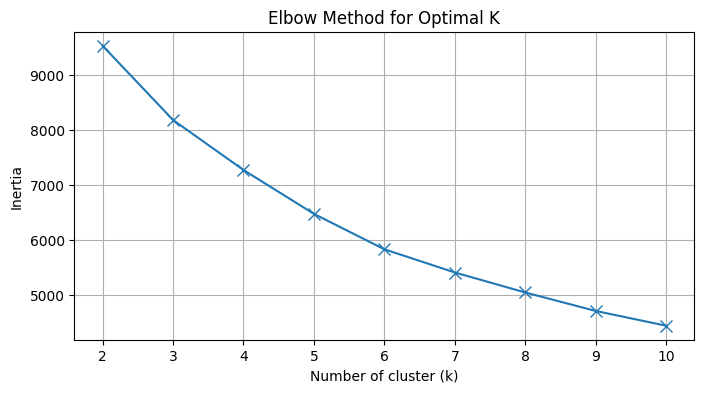

Inertia values for different k:
k=2: 9536.72
k=3: 8185.32
k=4: 7275.83
k=5: 6476.95
k=6: 5832.55
k=7: 5410.51
k=8: 5046.79
k=9: 4710.63
k=10: 4442.14


In [126]:
k_values = range(2, 11)
inertia_values = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_kmeans_scaled)
    inertia_values.append(kmeans.inertia_)

#Plot to find the Elbow
plt.figure(figsize=(8,4))
plt.plot(k_values, inertia_values, 'x-', markersize = 8)
plt.xlabel("Number of cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.grid(True)
plt.show()

print("Inertia values for different k:")
for k, inertia in zip(k_values, inertia_values):
    print(f"k={k}: {inertia:.2f}")

Look at the plot, choose k = 4 as it is the time inertia start to decrease significantly. As k = 3 is too low and k = 5 is to large to create clusters, 4 should be the good number of clusters to create.

# (c) (3 pts) Fit the final K-means model and assign training labels.

In [127]:
final_k = 4
kmeans_final = KMeans(n_clusters=final_k, random_state=42, n_init=10)

kmeans_final.fit(X_kmeans_scaled)

X_kmeans_raw['cluster_label'] = kmeans_final.labels_

print(f"K-Means model fitted with {final_k} clusters.")
print("Cluster labels assigned to X_kmeans_raw.")
X_kmeans_raw

K-Means model fitted with 4 clusters.
Cluster labels assigned to X_kmeans_raw.


,annual_inc,dti,total_acc,loan_amnt,term_months,emp_length_years,cluster_label
90763,120000.0,10.09,24.0,21000.0,36.0,10.0,2
8115,97333.0,8.46,48.0,10000.0,36.0,3.0,1
238147,99500.0,17.56,22.0,28000.0,60.0,10.0,0
200059,40000.0,26.43,30.0,7500.0,36.0,4.0,1
169185,220000.0,11.19,47.0,35000.0,36.0,3.0,2
...,...,...,...,...,...,...,...
240264,80000.0,8.66,31.0,16000.0,36.0,1.0,1
157789,62000.0,17.86,44.0,12800.0,36.0,1.0,1
234424,49767.0,30.84,31.0,14025.0,60.0,6.0,0
189392,27000.0,26.58,21.0,8000.0,36.0,8.0,3


# (d) (4 pts) Summarize cluster size and key financial features, then bring back default_flag after clustering to describe default patterns.

In [128]:
# Join default_flag back to the subsampled K-means data
cluster_summary_df = X_kmeans_raw.copy()
cluster_summary_df['default_flag'] = y_train.loc[X_kmeans_raw.index]

# Summarize cluster sizes, mean of features, and default rate
cluster_summary = cluster_summary_df.groupby('cluster_label').agg(
    cluster_size=('cluster_label', 'size'),
    avg_annual_inc=('annual_inc', 'mean'),
    avg_dti=('dti', 'mean'),
    avg_total_acc=('total_acc', 'mean'),
    avg_loan_amnt=('loan_amnt', 'mean'),
    avg_term_months=('term_months', 'mean'),
    avg_emp_length_years=('emp_length_years', 'mean'),
    default_rate=('default_flag', 'mean')
).round(2)

print("K-Means Cluster Summary:")
display(cluster_summary)

K-Means Cluster Summary:


,cluster_size,avg_annual_inc,avg_dti,avg_total_acc,avg_loan_amnt,avg_term_months,avg_emp_length_years,default_rate
cluster_label,,,,,,,,
0,435,77997.00,17.45,28.72,19441.21,60.00,6.32,0.31
1,729,55020.72,15.04,19.56,8793.62,36.33,2.58,0.17
2,231,153122.49,14.34,31.45,25375.22,37.14,5.85,0.18
3,605,65575.42,18.05,27.09,10573.64,36.00,8.90,0.15


(e) (5 pts) State which supervised approach you would deploy after weighing predictive performance and computation, which metric matters most, and one practical limitation or caveat from your HW3 results.

I would deploy the LDA model. When tuned with a threshold of 0.3, LDA achieved a Recall of 0.324 and Precision of 0.317 on the test set for the default class. This is significantly better than KNN (Recall 0.00), SVM (Recall 0.018), and the Decision Tree (Recall 0.00 with default threshold) which largely failed to identify any defaulting loans. While its overall accuracy was lower than some other models, its ability to detect defaults was good.

Most Important Metric: Recall for the Default Class. For the problem of predicting loan defaults, Recall is the most critical metric. A high recall means the model is effective at identifying a large proportion of actual defaulting loans. A False Negative can lead to significant financial losses for the lender, thus, we need to capture as many high-risk individuals as possible.

Limitation: It is hard to detect default correctly. This indicates that the models are heavily biased towards predicting the non-defaults. In a real-world scenario, this bias would result in missing a large number of actual defaulting loans, thus making the financial institution loosing money.